In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

import zipfile
import io
import requests

response = requests.get(url)

zip_file = zipfile.ZipFile(io.BytesIO(response.content))

print(zip_file.namelist())

['online_retail_II.xlsx']


In [3]:
df = pd.read_excel(
    io.BytesIO(zip_file.read("online_retail_II.xlsx")),
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [5]:
df.describe(include="all")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,525461.0,525461,522533,525461.000000,525461,525461.000000,417534.000000,525461
unique,28816.0,4632,4681,NaN,NaN,NaN,NaN,40
top,537434.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,675.0,3516,3549,NaN,NaN,NaN,NaN,485852
mean,NaN,NaN,NaN,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478,NaN
min,NaN,NaN,NaN,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2010-03-21 12:20:00,1.250000,13983.000000,NaN
50%,NaN,NaN,NaN,3.000000,2010-07-06 09:51:00,2.100000,15311.000000,NaN
75%,NaN,NaN,NaN,10.000000,2010-10-15 12:45:00,4.210000,16799.000000,NaN
max,NaN,NaN,NaN,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000,NaN


In [6]:
print("First 5 records:")

display(df.head())

print("Last 5 records:")

display(df.tail())

First 5 records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Last 5 records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525460,538171,21931,JUMBO STORAGE BAG SUKI,2,2010-12-09 20:01:00,1.95,17530.0,United Kingdom


In [7]:
rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 525461
Total Columns: 8


In [8]:
missing_values = df.isnull().sum()

print("Missing values:")

display(missing_values)

Missing values:


,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


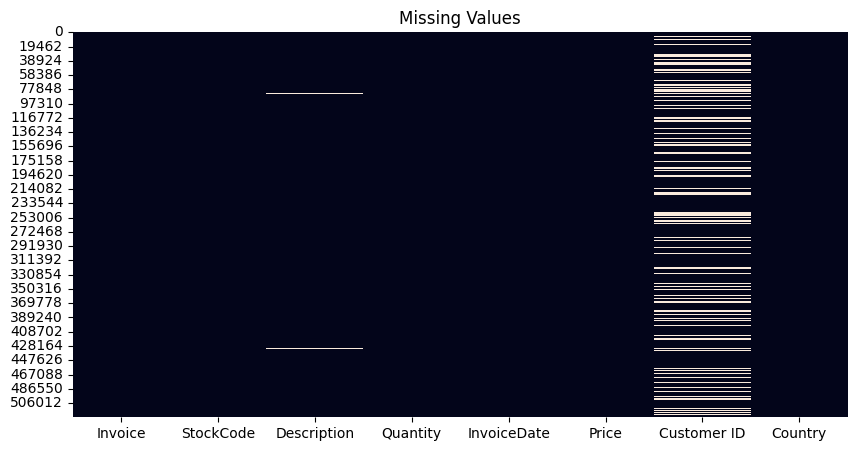

In [9]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values")

plt.show()

In [10]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 6865


In [11]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,525461.000000,525461.000000
mean,10.337667,4.688834
std,107.424110,146.126914
min,-9600.000000,-53594.360000
25%,1.000000,1.250000
50%,3.000000,2.100000
75%,10.000000,4.210000
max,19152.000000,25111.090000


In [12]:
print("Unique Customers:", df['Customer ID'].nunique())

print("Unique Products:", df['StockCode'].nunique())

print("Unique Countries:", df['Country'].nunique())

print("Unique Invoices:", df['Invoice'].nunique())

Unique Customers: 4383
Unique Products: 4632
Unique Countries: 40
Unique Invoices: 28816


In [13]:
df_clean = df.copy()

print("Working copy created!")

Working copy created!


In [14]:
df_clean.columns = df_clean.columns.str.strip()

print(df_clean.columns.tolist())


['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [15]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates()

after = len(df_clean)

print("Before:", before)

print("After:", after)

print("Duplicates removed:", before - after)


Before: 525461
After: 518596
Duplicates removed: 6865


In [16]:
print("Missing values:")

display(df_clean.isnull().sum())


Missing values:


,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107833
Country,0


In [17]:
df_clean = df_clean.dropna(subset=['StockCode'])

df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

df_clean['Country'] = df_clean['Country'].fillna('Unknown Country')

print("Missing values handled!")

Missing values handled!


In [18]:
df_clean['Customer ID'] = pd.to_numeric(
    df_clean['Customer ID'],
    errors='coerce'
)

df_clean['Quantity'] = pd.to_numeric(
    df_clean['Quantity'],
    errors='coerce'
)

df_clean['Price'] = pd.to_numeric(
    df_clean['Price'],
    errors='coerce'
)

df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'],
    errors='coerce'
)

print(df_clean.dtypes)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [19]:
df_clean = df_clean.dropna(subset=['InvoiceDate'])

print("Invalid dates removed!")

Invalid dates removed!


In [20]:
df_clean['Invoice'] = df_clean['Invoice'].astype(str)

df_clean['IsCancelled'] = df_clean['Invoice'].str.startswith('C')

print("Cancelled transactions:", df_clean['IsCancelled'].sum())

print("Normal transactions:", (~df_clean['IsCancelled']).sum())

Cancelled transactions: 10182
Normal transactions: 508414


In [21]:
df_sales = df_clean[
    (df_clean['IsCancelled'] == False) &
    (df_clean['Quantity'] > 0) &
    (df_clean['Price'] > 0)
].copy()

print("Original records:", len(df_clean))

print("Valid sales records:", len(df_sales))

Original records: 518596
Valid sales records: 504730


In [22]:
Q1 = df_sales['Price'].quantile(0.25)

Q3 = df_sales['Price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = df_sales[
    (df_sales['Price'] < lower) |
    (df_sales['Price'] > upper)
]

print("Price outliers:", len(outliers))

Price outliers: 33369


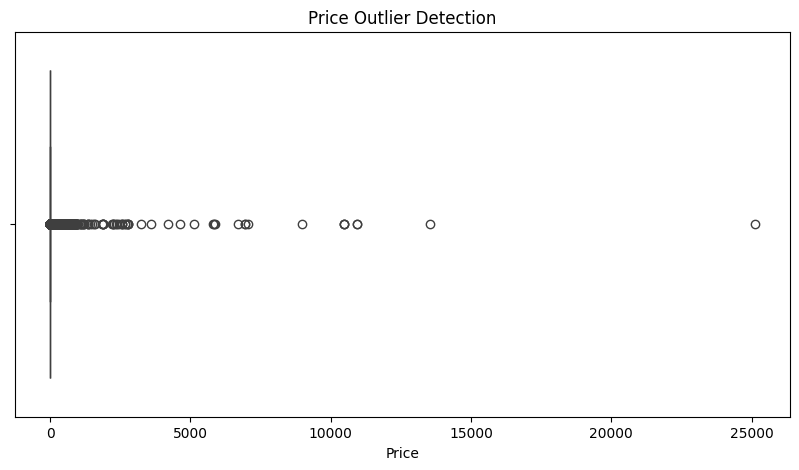

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sales['Price'])

plt.title("Price Outlier Detection")

plt.show()

In [24]:
customer_data = df_sales[['Customer ID', 'Country']].drop_duplicates()

customer_data = customer_data.dropna(subset=['Customer ID'])

display(customer_data.head())

,Customer ID,Country
0,13085.0,United Kingdom
12,13078.0,United Kingdom
31,15362.0,United Kingdom
54,18102.0,United Kingdom
71,12682.0,France


In [25]:
product_data = df_sales[
    ['StockCode', 'Description', 'Price']
].drop_duplicates(subset=['StockCode'])

display(product_data.head())


,StockCode,Description,Price
0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,6.95
1,79323P,PINK CHERRY LIGHTS,6.75
2,79323W,WHITE CHERRY LIGHTS,6.75
3,22041,"RECORD FRAME 7"" SINGLE SIZE",2.10
4,21232,STRAWBERRY CERAMIC TRINKET BOX,1.25


In [26]:
integrated_data = pd.merge(
    df_sales,
    customer_data,
    on='Customer ID',
    how='left'
)

print("Integrated data created!")

display(integrated_data.head())

Integrated data created!


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country_x,IsCancelled,Country_y
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,United Kingdom


In [27]:
print("Sales records:", len(df_sales))

print("Integrated records:", len(integrated_data))

print("Missing Customer IDs:", integrated_data['Customer ID'].isnull().sum())

Sales records: 504730
Integrated records: 505273
Missing Customer IDs: 103814


In [28]:
df_sales['TotalAmount'] = df_sales['Quantity'] * df_sales['Price']

display(df_sales.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


In [29]:
df_sales['Year'] = df_sales['InvoiceDate'].dt.year

df_sales['Month'] = df_sales['InvoiceDate'].dt.month

df_sales['MonthName'] = df_sales['InvoiceDate'].dt.month_name()

df_sales['Day'] = df_sales['InvoiceDate'].dt.day

df_sales['DayName'] = df_sales['InvoiceDate'].dt.day_name()

df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour

display(df_sales.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalAmount,Year,Month,MonthName,Day,DayName,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12,December,1,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,1,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,1,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12,December,1,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12,December,1,Tuesday,7


In [30]:
customer_metrics = df_sales.groupby('Customer ID').agg(
    TotalOrders=('Invoice', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

display(customer_metrics.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate
0,12346.0,11,70,372.86,11.298788,2010-06-28 13:53:00
1,12347.0,2,828,1323.32,18.638310,2010-12-07 14:57:00
2,12348.0,1,373,222.16,11.108000,2010-09-27 14:59:00
3,12349.0,3,993,2671.14,26.187647,2010-10-28 08:23:00
4,12351.0,1,261,300.93,14.330000,2010-11-29 15:23:00


In [31]:
customer_metrics['PurchaseFrequency'] = customer_metrics['TotalOrders']

customer_metrics['AverageQuantityPerOrder'] = (
    customer_metrics['TotalQuantity'] /
    customer_metrics['TotalOrders']
)

display(customer_metrics.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder
0,12346.0,11,70,372.86,11.298788,2010-06-28 13:53:00,11,6.363636
1,12347.0,2,828,1323.32,18.638310,2010-12-07 14:57:00,2,414.000000
2,12348.0,1,373,222.16,11.108000,2010-09-27 14:59:00,1,373.000000
3,12349.0,3,993,2671.14,26.187647,2010-10-28 08:23:00,3,331.000000
4,12351.0,1,261,300.93,14.330000,2010-11-29 15:23:00,1,261.000000


In [32]:
reference_date = df_sales['InvoiceDate'].max()

customer_metrics['Recency'] = (
    reference_date - customer_metrics['LastPurchaseDate']
).dt.days

display(customer_metrics[['Customer ID', 'LastPurchaseDate', 'Recency']].head())

,Customer ID,LastPurchaseDate,Recency
0,12346.0,2010-06-28 13:53:00,164
1,12347.0,2010-12-07 14:57:00,2
2,12348.0,2010-09-27 14:59:00,73
3,12349.0,2010-10-28 08:23:00,42
4,12351.0,2010-11-29 15:23:00,10


In [33]:
customer_data = customer_data.drop_duplicates(subset=['Customer ID'])

customer_data = pd.merge(
    customer_data,
    customer_metrics,
    on='Customer ID',
    how='left'
)

display(customer_data.head())

,Customer ID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency
0,13085.0,United Kingdom,6,728,2017.20,32.535484,2010-01-29 11:42:00,6,121.333333,314
1,13078.0,United Kingdom,32,6553,16904.51,38.159165,2010-12-08 09:07:00,32,204.781250,1
2,15362.0,United Kingdom,2,368,613.08,15.327000,2010-09-17 10:37:00,2,184.000000,83
3,18102.0,United Kingdom,89,124216,349164.35,556.880941,2010-12-09 13:44:00,89,1395.685393,0
4,12682.0,France,23,5443,11745.69,22.851537,2010-12-09 14:49:00,23,236.652174,0


In [34]:
product_metrics = df_sales.groupby('StockCode').agg(
    TotalUnitsSold=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    TotalTransactions=('Invoice', 'nunique'),
    AverageSellingPrice=('Price', 'mean')
).reset_index()

display(product_metrics.head())

,StockCode,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice
0,10002,7971,6333.76,310,0.967714
1,10080,12,10.20,5,0.850000
2,10109,4,1.68,1,0.420000
3,10120,487,105.57,47,0.256809
4,10125,853,761.66,81,1.012941


In [35]:
product_data = pd.merge(
    product_data,
    product_metrics,
    on='StockCode',
    how='left'
)

display(product_data.head())

,StockCode,Description,Price,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice
0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,6.95,1390,10868.59,279,9.168901
1,79323P,PINK CHERRY LIGHTS,6.75,2277,13760.93,264,7.285925
2,79323W,WHITE CHERRY LIGHTS,6.75,3004,18048.72,349,7.030000
3,22041,"RECORD FRAME 7"" SINGLE SIZE",2.10,3487,8016.90,211,3.306887
4,21232,STRAWBERRY CERAMIC TRINKET BOX,1.25,27059,34411.68,1640,1.465954


In [36]:
date_data = df_sales[
    ['InvoiceDate', 'Year', 'Month', 'MonthName', 'Day', 'DayName', 'Hour']
].drop_duplicates()

date_data['DateKey'] = (
    date_data['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

date_data = date_data.drop_duplicates(subset=['DateKey'])

display(date_data.head())

,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2009-12-01 07:45:00,2009,12,December,1,Tuesday,7,20091201
3223,2009-12-02 08:15:00,2009,12,December,2,Wednesday,8,20091202
6500,2009-12-03 07:25:00,2009,12,December,3,Thursday,7,20091203
9502,2009-12-04 08:24:00,2009,12,December,4,Friday,8,20091204
12061,2009-12-05 10:11:00,2009,12,December,5,Saturday,10,20091205


In [37]:
customer_data = customer_data.reset_index(drop=True)

customer_data['CustomerKey'] = range(1, len(customer_data) + 1)

display(customer_data.head())

,Customer ID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency,CustomerKey
0,13085.0,United Kingdom,6,728,2017.20,32.535484,2010-01-29 11:42:00,6,121.333333,314,1
1,13078.0,United Kingdom,32,6553,16904.51,38.159165,2010-12-08 09:07:00,32,204.781250,1,2
2,15362.0,United Kingdom,2,368,613.08,15.327000,2010-09-17 10:37:00,2,184.000000,83,3
3,18102.0,United Kingdom,89,124216,349164.35,556.880941,2010-12-09 13:44:00,89,1395.685393,0,4
4,12682.0,France,23,5443,11745.69,22.851537,2010-12-09 14:49:00,23,236.652174,0,5


In [38]:
product_data = product_data.reset_index(drop=True)

product_data['ProductKey'] = range(1, len(product_data) + 1)

display(product_data.head())

,StockCode,Description,Price,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice,ProductKey
0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,6.95,1390,10868.59,279,9.168901,1
1,79323P,PINK CHERRY LIGHTS,6.75,2277,13760.93,264,7.285925,2
2,79323W,WHITE CHERRY LIGHTS,6.75,3004,18048.72,349,7.030000,3
3,22041,"RECORD FRAME 7"" SINGLE SIZE",2.10,3487,8016.90,211,3.306887,4
4,21232,STRAWBERRY CERAMIC TRINKET BOX,1.25,27059,34411.68,1640,1.465954,5


In [39]:
fact_sales = df_sales.copy()

fact_sales = pd.merge(
    fact_sales,
    customer_data[['Customer ID', 'CustomerKey']],
    on='Customer ID',
    how='left'
)

fact_sales = pd.merge(
    fact_sales,
    product_data[['StockCode', 'ProductKey']],
    on='StockCode',
    how='left'
)

fact_sales['DateKey'] = (
    fact_sales['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

display(fact_sales.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalAmount,Year,Month,MonthName,Day,DayName,Hour,CustomerKey,ProductKey,DateKey
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12,December,1,Tuesday,7,1.0,1,20091201
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,1,Tuesday,7,1.0,2,20091201
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,1,Tuesday,7,1.0,3,20091201
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12,December,1,Tuesday,7,1.0,4,20091201
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12,December,1,Tuesday,7,1.0,5,20091201


In [40]:
fact_sales = fact_sales[
    [
        'Invoice',
        'CustomerKey',
        'ProductKey',
        'DateKey',
        'Quantity',
        'Price',
        'TotalAmount'
    ]
]

display(fact_sales.head())

,Invoice,CustomerKey,ProductKey,DateKey,Quantity,Price,TotalAmount
0,489434,1.0,1,20091201,12,6.95,83.4
1,489434,1.0,2,20091201,12,6.75,81.0
2,489434,1.0,3,20091201,12,6.75,81.0
3,489434,1.0,4,20091201,48,2.10,100.8
4,489434,1.0,5,20091201,24,1.25,30.0


In [41]:
print("Fact Sales Table:", fact_sales.shape)

print("Customer Dimension:", customer_data.shape)

print("Product Dimension:", product_data.shape)

print("Date Dimension:", date_data.shape)

Fact Sales Table: (504730, 7)
Customer Dimension: (4312, 11)
Product Dimension: (4251, 8)
Date Dimension: (307, 8)


In [42]:
print("Unique Customer Keys:", customer_data['CustomerKey'].nunique())

print("Unique Product Keys:", product_data['ProductKey'].nunique())

print("Unique Date Keys:", date_data['DateKey'].nunique())

Unique Customer Keys: 4312
Unique Product Keys: 4251
Unique Date Keys: 307


In [43]:
customer_metrics['RecencyCategory'] = pd.qcut(
    customer_metrics['Recency'].rank(method='first'),
    q=3,
    labels=['Recent', 'Moderate', 'At Risk']
)

customer_metrics['FrequencyCategory'] = pd.qcut(
    customer_metrics['TotalOrders'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

customer_metrics['MonetaryCategory'] = pd.qcut(
    customer_metrics['TotalRevenue'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

display(customer_metrics.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency,RecencyCategory,FrequencyCategory,MonetaryCategory
0,12346.0,11,70,372.86,11.298788,2010-06-28 13:53:00,11,6.363636,164,At Risk,High,Low
1,12347.0,2,828,1323.32,18.638310,2010-12-07 14:57:00,2,414.000000,2,Recent,Low,High
2,12348.0,1,373,222.16,11.108000,2010-09-27 14:59:00,1,373.000000,73,Moderate,Low,Low
3,12349.0,3,993,2671.14,26.187647,2010-10-28 08:23:00,3,331.000000,42,Moderate,Medium,High
4,12351.0,1,261,300.93,14.330000,2010-11-29 15:23:00,1,261.000000,10,Recent,Low,Low


In [44]:
customer_data = pd.merge(
    customer_data,
    customer_metrics[
        ['Customer ID', 'RecencyCategory',
         'FrequencyCategory', 'MonetaryCategory']
    ],
    on='Customer ID',
    how='left'
)

display(customer_data.head())

,Customer ID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency,CustomerKey,RecencyCategory,FrequencyCategory,MonetaryCategory
0,13085.0,United Kingdom,6,728,2017.20,32.535484,2010-01-29 11:42:00,6,121.333333,314,1,At Risk,High,High
1,13078.0,United Kingdom,32,6553,16904.51,38.159165,2010-12-08 09:07:00,32,204.781250,1,2,Recent,High,High
2,15362.0,United Kingdom,2,368,613.08,15.327000,2010-09-17 10:37:00,2,184.000000,83,3,Moderate,Medium,Medium
3,18102.0,United Kingdom,89,124216,349164.35,556.880941,2010-12-09 13:44:00,89,1395.685393,0,4,Recent,High,High
4,12682.0,France,23,5443,11745.69,22.851537,2010-12-09 14:49:00,23,236.652174,0,5,Recent,High,High


In [45]:
print("Missing values:")

display(fact_sales.isnull().sum())

print("Duplicates:", fact_sales.duplicated().sum())

Missing values:


,0
Invoice,0
CustomerKey,103814
ProductKey,0
DateKey,0
Quantity,0
Price,0
TotalAmount,0


Duplicates: 1


In [46]:
display(customer_data.isnull().sum())

print("Duplicate Customer IDs:",
      customer_data['Customer ID'].duplicated().sum())

,0
Customer ID,0
Country,0
TotalOrders,0
TotalQuantity,0
TotalRevenue,0
AverageOrderValue,0
LastPurchaseDate,0
PurchaseFrequency,0
AverageQuantityPerOrder,0
Recency,0


Duplicate Customer IDs: 0


In [47]:
display(product_data.isnull().sum())

print("Duplicate Products:",
      product_data['StockCode'].duplicated().sum())

,0
StockCode,0
Description,0
Price,0
TotalUnitsSold,0
TotalRevenue,0
TotalTransactions,0
AverageSellingPrice,0
ProductKey,0


Duplicate Products: 0


In [48]:
display(date_data.isnull().sum())

print("Duplicate Date Keys:",
      date_data['DateKey'].duplicated().sum())

,0
InvoiceDate,0
Year,0
Month,0
MonthName,0
Day,0
DayName,0
Hour,0
DateKey,0


Duplicate Date Keys: 0


In [49]:
fact_sales.to_csv('fact_sales.csv', index=False)

customer_data.to_csv('dim_customer.csv', index=False)

product_data.to_csv('dim_product.csv', index=False)

date_data.to_csv('dim_date.csv', index=False)

print("All files saved successfully!")

All files saved successfully!


In [50]:
yearly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

rollup_result = yearly_sales.groupby('Year').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('Invoice', 'nunique')
).reset_index()

display(rollup_result)

,Year,TotalRevenue,TotalQuantity,TotalTransactions
0,2009,822483.950,425461,1682
1,2010,9449278.714,5387486,19269


In [51]:
monthly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year', 'Month', 'MonthName']],
    on='DateKey',
    how='left'
)

drilldown_result = monthly_sales.groupby(
    ['Year', 'Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('Invoice', 'nunique')
).reset_index()

drilldown_result = drilldown_result.sort_values(['Year', 'Month'])

display(drilldown_result)

,Year,Month,MonthName,TotalRevenue,TotalQuantity,TotalTransactions
0,2009,12,December,822483.950,425461,1682
1,2010,1,January,651155.112,390672,1105
2,2010,2,February,551504.726,381879,1201
3,2010,3,March,830915.261,526026,1681
4,2010,4,April,678875.252,366705,1462
5,2010,5,May,657705.500,395868,1500
6,2010,6,June,749537.310,406820,1645
7,2010,7,July,648810.270,337895,1529
8,2010,8,August,695251.910,472380,1425
9,2010,9,September,921696.991,583864,1839


In [52]:
selected_year = monthly_sales['Year'].max()

slice_result = monthly_sales[
    monthly_sales['Year'] == selected_year
]

slice_result = slice_result.groupby(
    ['Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('Invoice', 'nunique')
).reset_index()

slice_result = slice_result.sort_values('Month')

display(slice_result)

,Month,MonthName,TotalRevenue,TotalQuantity,TotalTransactions
0,1,January,651155.112,390672,1105
1,2,February,551504.726,381879,1201
2,3,March,830915.261,526026,1681
3,4,April,678875.252,366705,1462
4,5,May,657705.500,395868,1500
5,6,June,749537.310,406820,1645
6,7,July,648810.270,337895,1529
7,8,August,695251.910,472380,1425
8,9,September,921696.991,583864,1839
9,10,October,1161902.220,619996,2301


In [53]:
dice_result = monthly_sales[
    (monthly_sales['Year'] == selected_year) &
    (monthly_sales['Month'].isin([1, 2, 3])) &
    (monthly_sales['TotalAmount'] > 100)
]

dice_summary = dice_result.groupby(
    ['Year', 'Month']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('Invoice', 'nunique')
).reset_index()

display(dice_summary)

,Year,Month,TotalRevenue,TotalQuantity,TotalTransactions
0,2010,1,268330.12,184279,281
1,2010,2,182512.25,173962,262
2,2010,3,307135.52,233400,393


In [54]:
pivot_result = monthly_sales.pivot_table(
    index='Year',
    columns='MonthName',
    values='TotalAmount',
    aggfunc='sum',
    fill_value=0
)

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

pivot_result = pivot_result.reindex(
    columns=month_order,
    fill_value=0
)

display(pivot_result)

MonthName,January,February,March,April,May,June,July,August,September,October,November,December
Year,,,,,,,,,,,,
2009,0.000,0.000,0.000,0.000,0.0,0.00,0.00,0.00,0.000,0.00,0.000,822483.95
2010,651155.112,551504.726,830915.261,678875.252,657705.5,749537.31,648810.27,695251.91,921696.991,1161902.22,1464293.142,437631.02


In [55]:
reference_date = df_sales['InvoiceDate'].max()

cutoff_date = reference_date - pd.Timedelta(days=90)

print("Reference Date:", reference_date)

print("Cutoff Date:", cutoff_date)

Reference Date: 2010-12-09 20:01:00
Cutoff Date: 2010-09-10 20:01:00


In [56]:
historical_data = df_sales[
    (df_sales['InvoiceDate'] < cutoff_date) &
    (df_sales['Customer ID'].notnull())
].copy()

future_data = df_sales[
    (df_sales['InvoiceDate'] >= cutoff_date) &
    (df_sales['Customer ID'].notnull())
].copy()

print("Historical records:", len(historical_data))

print("Future records:", len(future_data))

Historical records: 253543
Future records: 147373


In [57]:
churn_features = historical_data.groupby('Customer ID').agg(
    TotalOrders=('Invoice', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    AverageUnitPrice=('Price', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

display(churn_features.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate
0,12346.0,11,70,372.86,11.298788,6.253333,2010-06-28 13:53:00
1,12349.0,2,474,1268.52,26.989787,8.395319,2010-05-18 09:57:00
2,12355.0,1,303,488.21,22.191364,2.399091,2010-05-21 11:59:00
3,12358.0,2,590,1697.93,48.512286,3.442571,2010-06-07 12:28:00
4,12359.0,5,877,2012.03,23.395698,5.170349,2010-06-22 10:24:00


In [58]:
churn_features['Recency'] = (
    cutoff_date - churn_features['LastPurchaseDate']
).dt.days

display(churn_features.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate,Recency
0,12346.0,11,70,372.86,11.298788,6.253333,2010-06-28 13:53:00,74
1,12349.0,2,474,1268.52,26.989787,8.395319,2010-05-18 09:57:00,115
2,12355.0,1,303,488.21,22.191364,2.399091,2010-05-21 11:59:00,112
3,12358.0,2,590,1697.93,48.512286,3.442571,2010-06-07 12:28:00,95
4,12359.0,5,877,2012.03,23.395698,5.170349,2010-06-22 10:24:00,80


In [59]:
future_customers = future_data.groupby('Customer ID').agg(
    FutureOrders=('Invoice', 'nunique')
).reset_index()

display(future_customers.head())

,Customer ID,FutureOrders
0,12347.0,2
1,12348.0,1
2,12349.0,1
3,12351.0,1
4,12352.0,2


In [60]:
churn_features = pd.merge(
    churn_features,
    future_customers,
    on='Customer ID',
    how='left'
)

churn_features['FutureOrders'] = churn_features['FutureOrders'].fillna(0)

churn_features['Churn'] = (
    churn_features['FutureOrders'] == 0
).astype(int)

display(churn_features.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate,Recency,FutureOrders,Churn
0,12346.0,11,70,372.86,11.298788,6.253333,2010-06-28 13:53:00,74,0.0,1
1,12349.0,2,474,1268.52,26.989787,8.395319,2010-05-18 09:57:00,115,1.0,0
2,12355.0,1,303,488.21,22.191364,2.399091,2010-05-21 11:59:00,112,0.0,1
3,12358.0,2,590,1697.93,48.512286,3.442571,2010-06-07 12:28:00,95,1.0,0
4,12359.0,5,877,2012.03,23.395698,5.170349,2010-06-22 10:24:00,80,1.0,0


In [62]:
if 'FutureOrders' not in churn_features.columns:
    churn_features = pd.merge(
        churn_features,
        future_customers,
        on='Customer ID',
        how='left'
    )

churn_features['FutureOrders'] = churn_features['FutureOrders'].fillna(0)

churn_features['Churn'] = (
    churn_features['FutureOrders'] == 0
).astype(int)

display(churn_features.head())

,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate,Recency,FutureOrders_x,Churn,FutureOrders_y,FutureOrders
0,12346.0,11,70,372.86,11.298788,6.253333,2010-06-28 13:53:00,74,0.0,1,NaN,0.0
1,12349.0,2,474,1268.52,26.989787,8.395319,2010-05-18 09:57:00,115,1.0,0,1.0,1.0
2,12355.0,1,303,488.21,22.191364,2.399091,2010-05-21 11:59:00,112,0.0,1,NaN,0.0
3,12358.0,2,590,1697.93,48.512286,3.442571,2010-06-07 12:28:00,95,1.0,0,1.0,1.0
4,12359.0,5,877,2012.03,23.395698,5.170349,2010-06-22 10:24:00,80,1.0,0,1.0,1.0


In [74]:
columns_to_drop = [col for col in churn_features.columns if '_x' in col or '_y' in col]
if columns_to_drop:
    churn_features = churn_features.drop(columns=columns_to_drop)

print("Cleaned Columns:")
display(churn_features.head())

Cleaned Columns:


,Customer ID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate,Recency,Churn,FutureOrders
0,12346.0,11,70,372.86,11.298788,6.253333,2010-06-28 13:53:00,74,1,0.0
1,12349.0,2,474,1268.52,26.989787,8.395319,2010-05-18 09:57:00,115,0,1.0
2,12355.0,1,303,488.21,22.191364,2.399091,2010-05-21 11:59:00,112,1,0.0
3,12358.0,2,590,1697.93,48.512286,3.442571,2010-06-07 12:28:00,95,0,1.0
4,12359.0,5,877,2012.03,23.395698,5.170349,2010-06-22 10:24:00,80,0,1.0


Churn
0    1942
1    1435
Name: count, dtype: int64


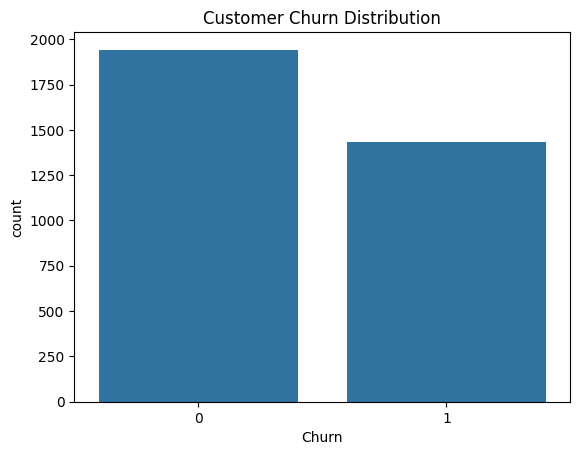

In [63]:
print(churn_features['Churn'].value_counts())

sns.countplot(x=churn_features['Churn'])

plt.title("Customer Churn Distribution")

plt.show()

In [64]:
features = [
    'TotalOrders',
    'TotalQuantity',
    'TotalRevenue',
    'AverageOrderValue',
    'AverageUnitPrice',
    'Recency'
]

X = churn_features[features]

y = churn_features['Churn']

print("Features selected!")

Features selected!


In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (2701, 6)
Testing data: (676, 6)


In [66]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [67]:
y_pred = rf_model.predict(X_test)

y_pred_probability = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated!")

Predictions generated!


In [68]:
results = pd.DataFrame({
    'Actual_Churn': y_test.values,
    'Predicted_Churn': y_pred,
    'Churn_Probability': y_pred_probability
})

display(results.head(10))

,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.33
1,1,0,0.45
2,0,1,0.74
3,0,0,0.20
4,1,1,0.58
5,1,1,0.66
6,0,0,0.11
7,0,1,0.57
8,1,1,0.85
9,0,1,0.59


In [69]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 63.02 %


In [70]:
precision = precision_score(y_test, y_pred, zero_division=0)

print("Precision:", round(precision * 100, 2), "%")

Precision: 57.03 %


In [71]:
recall = recall_score(y_test, y_pred, zero_division=0)

print("Recall:", round(recall * 100, 2), "%")

Recall: 52.26 %


In [72]:
f1 = f1_score(y_test, y_pred, zero_division=0)

print("F1 Score:", round(f1 * 100, 2), "%")

F1 Score: 54.55 %


In [73]:
print("========== MODEL EVALUATION ==========")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision * 100, 2), "%")

print("Recall:", round(recall * 100, 2), "%")

print("F1 Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(y_test, y_pred, zero_division=0))

========== MODEL EVALUATION ==========
Accuracy: 63.02 %
Precision: 57.03 %
Recall: 52.26 %
F1 Score: 54.55 %

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.71      0.69       389
           1       0.57      0.52      0.55       287

    accuracy                           0.63       676
   macro avg       0.62      0.62      0.62       676
weighted avg       0.63      0.63      0.63       676

